# Multilingual relatedness: data, learned model and selected inference

The model scores sentence pairs from the complete nine-language human-source-compatible SemRel2024 cohort. Five official training languages provide 5,640 pairs; all nine provide 1,347 development and 3,969 test pairs after text-only duplicate guards. No generated fine-tuning pairs are added.

The selected scorer combines **25% of a trained three-seed E5 ranking MLP with 75% Unicode character overlap**, using one global weight for every language. Its development macro Spearman is **0.53164**, versus **0.45429** for the strongest fixed baseline. Selection requires a gain of at least 0.005 and no language loss greater than 0.02.

This notebook contains the actual preprocessing, encoder, feature, model, loss, training-loop and scoring definitions. Recorded full-cloud training histories are identified as such. Default execution prepares the complete source again, performs two real gradient updates as a smoke check, and replays the saved selected model on every development pair. It does not reopen test gold.

In [1]:
from pathlib import Path
import os, sys, json, math, csv, re, hashlib, unicodedata, copy, time, io, contextlib
from datetime import datetime, timezone
from urllib.request import urlopen
import numpy as np
import pandas as pd
import torch
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT));torch.set_num_threads(2)
LANGUAGES=('afr','amh','arb','arq','ary','hau','ind','kin','pan')
TRAIN_LANGUAGES=('amh','arq','ary','hau','kin')
from src.config import DATA_REVISION
COVERAGE=ROOT/'docs/full-cohort-v3-coverage.json'
PROCESSED=ROOT/'data/processed/semrel-full-v3'
ARTIFACTS=Path(os.environ.get('SEMREL_RUN',str(ROOT/'data/features')))
SELECTED=ROOT/'models/selected'
FIGURES=ROOT/'assets/figures';FIGURES.mkdir(parents=True,exist_ok=True)
RUN=ROOT/'data/interim'/('notebook-'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
def sha(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def show(fig,name):
    fig.tight_layout(pad=1.5,w_pad=3);fig.savefig(FIGURES/name,dpi=140,bbox_inches='tight');display(fig);plt.close(fig)
results=json.loads((ROOT/'docs/training-results.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'languages':len(LANGUAGES),'training_languages':len(TRAIN_LANGUAGES),**results['data']['prepared_counts'],'training_device':'private cloud CPU','threads':results['training_run']['threads'],'encoding_and_training_seconds':results['training_run']['seconds']}]))

,languages,training_languages,train,dev,test,training_device,threads,encoding_and_training_seconds
0,9,5,5640,1347,3969,private cloud CPU,2,1992.765741


## Complete source preparation

The reader validates official schemas and bounded human scores. Test calls use `labels=False`; the test score column is never parsed. Duplicate guards compare normalized text only. Source bytes and row counts are pinned before any fitting.

In [2]:
def normalized(text):
    return ' '.join(unicodedata.normalize('NFKC', text).casefold().split())

def pair_key(row):
    return tuple(sorted((normalized(row['sentence1']), normalized(row['sentence2']))))

def read(path, language, labels):
    result = []
    seen = set()
    with Path(path).open(encoding='utf-8-sig', newline='') as handle:
        reader = csv.DictReader(handle, strict=True)
        if reader.fieldnames is None or len(reader.fieldnames) != 3 or set(reader.fieldnames) not in ({'PairID', 'Text', 'Score'}, {'PairID', 'Text', 'score'}):
            raise ValueError('Unexpected official schema')
        for row in reader:
            if None in row or any((v is None for v in row.values())):
                raise ValueError('Malformed source row')
            parts = row['Text'].split('\n')
            if language == 'afr' and len(parts) == 1 and (row['Text'].count('\t') == 1):
                parts = row['Text'].split('\t')
            if len(parts) != 2 or not all((p.strip() for p in parts)):
                raise ValueError('Invalid sentence pair')
            if not row['PairID'] or row['PairID'] in seen:
                raise ValueError('Invalid repeated ID')
            seen.add(row['PairID'])
            item = {'id': row['PairID'], 'language': language, 'sentence1': parts[0], 'sentence2': parts[1]}
            if labels:
                score = float(row.get('Score', row.get('score')))
                if not math.isfinite(score) or not 0 <= score <= 1:
                    raise ValueError('Invalid human score')
                item['target'] = score
            result.append(item)
    return result

def prepare(raw, output, coverage=COVERAGE):
    raw = Path(raw)
    output = Path(output)
    if output.exists():
        raise ValueError('Fresh full-cohort output required')
    coverage = Path(coverage)
    report = json.loads(coverage.read_text(encoding='utf-8'))
    languages = tuple(report['included_languages'])
    if report['revision'] != DATA_REVISION or languages not in (LANGUAGES[:-1], LANGUAGES):
        raise ValueError('Coverage contract changed')
    raw.mkdir(parents=True, exist_ok=True)
    splits = {'train': [], 'dev': [], 'test': []}
    audit = {}
    for language in languages:
        rows = {}
        for split in ('train', 'dev', 'test'):
            key = language + '_' + split
            if key not in report['files']:
                rows[split] = []
                continue
            contract = report['files'][key]
            path = raw / Path(contract['path']).name
            if not path.exists():
                path.write_bytes(urlopen(contract['url'], timeout=60).read())
            if hashlib.sha256(path.read_bytes()).hexdigest() != contract['sha256']:
                raise ValueError('Changed official source')
            rows[split] = read(path, language, split != 'test')
            if len(rows[split]) != contract['rows']:
                raise ValueError('Changed source count')
        original = {s: len(v) for s, v in rows.items()}
        test_keys = {pair_key(r) for r in rows['test']}
        rows['dev'] = [r for r in rows['dev'] if pair_key(r) not in test_keys]
        protected = test_keys | {pair_key(r) for r in rows['dev']}
        seen = set()
        kept = []
        for row in rows['train']:
            key = pair_key(row)
            if key not in protected and key not in seen:
                kept.append(row)
                seen.add(key)
        rows['train'] = kept
        audit[language] = {'official': original, 'prepared': {s: len(v) for s, v in rows.items()}, 'removed_training_duplicates_or_protected_pairs': original['train'] - len(kept), 'removed_development_pairs_duplicating_test': original['dev'] - len(rows['dev']), 'test_unchanged': len(rows['test']) == original['test']}
        for split in splits:
            splits[split].extend(rows[split])
    output.mkdir(parents=True)
    hashes = {}
    for split, rows in splits.items():
        p = output / (split + '.jsonl')
        p.write_text(''.join((json.dumps(r, ensure_ascii=False) + '\n' for r in rows)), encoding='utf-8', newline='\n')
        hashes[split] = hashlib.sha256(p.read_bytes()).hexdigest()
    result = {'languages': audit, 'processed_sha256': hashes, 'test_gold_parsed': False, 'scope': report['scope'], 'coverage_sha256': hashlib.sha256(coverage.read_bytes()).hexdigest(), 'previously_observed_test_languages': ['amh', 'hau', 'kin'], 'selection_languages': list(languages), 'training_languages': list(TRAIN_LANGUAGES)}
    (output / 'audit.json').write_text(json.dumps(result, indent=2) + '\n', encoding='utf-8', newline='\n')
    print(json.dumps(result, indent=2))
    return result

In [3]:
with contextlib.redirect_stdout(io.StringIO()):
    prepared=prepare(ROOT/'data/raw/semrel-full-v3',RUN,COVERAGE)
assert prepared['processed_sha256']==results['training_run'].get('processed_sha256',prepared['processed_sha256'])
for split,digest in prepared['processed_sha256'].items():assert sha(PROCESSED/(split+'.jsonl'))==digest
print({'prepared_pairs':{split:sum(row['prepared'][split] for row in prepared['languages'].values()) for split in ('train','dev','test')},'test_scores_parsed':prepared['test_gold_parsed'],'source_revision':DATA_REVISION})

{'prepared_pairs': {'train': 5640, 'dev': 1347, 'test': 3969}, 'test_scores_parsed': False, 'source_revision': '3c5941ddffdc9d833a5528f49dd13ed9087c0dba'}


## Pinned sentence encoder and symmetric features

E5 uses `query: ` on both sentences, masked mean pooling and unit normalization. The pinned safetensor hash is checked before loading; missing or mismatched backbone keys fail closed. No pooler is randomly initialized or used. Encoder allocation is shown here but is not performed on this limited-memory notebook host; the actual cloud proof is included in the inference notebook.

Absolute differences, products, cosine and two lexical scores form 1,539 symmetric features. Train-only moments standardize the learned head.

In [4]:
VARIANTS={'afro': {'license': 'MIT',
          'model': 'Davlan/afro-xlmr-base',
          'prefix': '',
          'revision': '25f27299c247a6b73a767bd82d12444138b19337',
          'sha256': 'f73b04316c9c2e76fcb213957616a09e1eb44112266717f649fc1897dac42953'},
 'e5': {'license': 'MIT',
        'model': 'intfloat/multilingual-e5-base',
        'prefix': 'query: ',
        'revision': 'd128750597153bb5987e10b1c3493a34e5a4502a',
        'sha256': 'a18a44fad1d0b46ded15928144138cff1135d5cc8233bdd90be5f18822de09a7'}}

def pool_and_normalize(hidden, mask):
    import torch
    if hidden.ndim != 3 or mask.shape != hidden.shape[:2] or (not torch.isfinite(hidden).all()) or (not ((mask == 0) | (mask == 1)).all()) or (not mask.any(1).all()):
        raise ValueError('Aligned finite states and nonempty binary masks required')
    weights = mask.unsqueeze(-1).to(hidden.dtype)
    pooled = (hidden * weights).sum(1) / weights.sum(1)
    norm = pooled.norm(dim=1, keepdim=True)
    if not (norm > 0).all():
        raise ValueError('Zero sentence embedding')
    return pooled / norm

class Encoder:

    def __init__(self, variant, max_tokens=512):
        import torch
        from transformers import AutoModel, AutoTokenizer
        from huggingface_hub import hf_hub_download
        if variant not in VARIANTS or max_tokens not in (128, 512):
            raise ValueError('Unsupported encoder contract')
        self.spec = VARIANTS[variant]
        self.variant = variant
        self.max_tokens = max_tokens
        self.torch = torch
        torch.set_num_threads(2)
        weight = hf_hub_download(self.spec['model'], 'model.safetensors', revision=self.spec['revision'])
        with Path(weight).open('rb') as h:
            actual = hashlib.file_digest(h, 'sha256').hexdigest()
        if actual != self.spec['sha256']:
            raise ValueError('Pinned encoder weight mismatch')
        self.tokenizer = AutoTokenizer.from_pretrained(self.spec['model'], revision=self.spec['revision'], trust_remote_code=False)
        self.model, info = AutoModel.from_pretrained(self.spec['model'], revision=self.spec['revision'], use_safetensors=True, add_pooling_layer=False, output_loading_info=True, trust_remote_code=False)
        if any((info.get(k) for k in ('missing_keys', 'mismatched_keys', 'error_msgs'))):
            raise ValueError('Incomplete pretrained backbone')
        allowed = {'pooler.dense.weight', 'pooler.dense.bias'}
        if any((k not in allowed and (not (variant == 'afro' and k.startswith('lm_head.'))) for k in info.get('unexpected_keys', []))):
            raise ValueError('Unexpected encoder parameters')
        self.model = self.model.eval().requires_grad_(False)
        self.loading = info

    def encode(self, texts, batch_size=16):
        if not texts or any((not isinstance(t, str) or not t.strip() for t in texts)):
            raise ValueError('Nonempty real source sentences required')
        output = []
        truncated = 0
        maximum = 0
        for start in range(0, len(texts), batch_size):
            prefixed = [self.spec['prefix'] + t for t in texts[start:start + batch_size]]
            lengths = [len(t) for t in self.tokenizer(prefixed, truncation=False)['input_ids']]
            truncated += sum((n > self.max_tokens for n in lengths))
            maximum = max(maximum, max(lengths))
            tokens = self.tokenizer(prefixed, padding=True, truncation=True, max_length=self.max_tokens, return_tensors='pt')
            with self.torch.inference_mode():
                values = pool_and_normalize(self.model(**tokens).last_hidden_state, tokens['attention_mask'])
            output.append(values.numpy().astype(np.float32))
        return (np.concatenate(output), {'sentences': len(texts), 'truncated_sentences': truncated, 'maximum_untruncated_tokens': maximum})

In [5]:
def jaccard(a, b):
    union = a | b
    return len(a & b) / len(union) if union else 0.0

def lexical(rows):
    values = []
    for row in rows:
        a, b = (normalized(row['sentence1']), normalized(row['sentence2']))
        words = lambda text: set(re.findall('\\w+', text, flags=re.UNICODE))
        grams = lambda text: {text[i:i + 3] for i in range(max(0, len(text) - 2))}
        values.append([jaccard(words(a), words(b)), jaccard(grams(a), grams(b))])
    return np.asarray(values, dtype=np.float32)

def pair_features(embeddings, rows):
    e = np.asarray(embeddings, dtype=np.float32)
    if e.ndim != 3 or e.shape[:2] != (len(rows), 2) or (not len(rows)) or (not np.isfinite(e).all()):
        raise ValueError('Expected aligned finite pair embeddings')
    norms = np.linalg.norm(e.astype(np.float64), axis=2, keepdims=True)
    if (norms <= 0).any():
        raise ValueError('Zero embedding')
    e = (e / norms).astype(np.float32)
    a, b = (e[:, 0], e[:, 1])
    cosine = np.sum(a * b, axis=1, keepdims=True)
    values = np.concatenate([np.abs(a - b), a * b, cosine, lexical(rows)], axis=1)
    if not np.isfinite(values).all():
        raise ValueError('Nonfinite pair features')
    return values

def fit_scaler(values):
    x = np.asarray(values, dtype=np.float64)
    if x.ndim != 2 or not len(x) or (not np.isfinite(x).all()):
        raise ValueError('Finite nonempty training features required')
    return (x.mean(axis=0).astype(np.float32), np.maximum(x.std(axis=0), 1e-05).astype(np.float32))

def scale(values, mean, std):
    x = np.asarray(values, dtype=np.float32)
    mean = np.asarray(mean)
    std = np.asarray(std)
    if x.ndim != 2 or mean.shape != (x.shape[1],) or std.shape != mean.shape or (not np.isfinite(mean).all()) or (not np.isfinite(std).all()) or (std <= 0).any():
        raise ValueError('Invalid persisted normalization')
    result = (x - mean) / std
    if not np.isfinite(result).all():
        raise ValueError('Nonfinite normalized features')
    return result

## The trained model, language balance and ranking objective

The MLP has 128 hidden units and dropout 0.2. AdamW uses LR 0.001, decay 0.01 and batch 64. Training weights equalize the five languages; the optional ranking term compares human-score differences of at least 0.1 within a language. The selected component uses ranking weight 0.1.

Each seed saves the earliest best development checkpoint, with a 50-epoch maximum, three-epoch minimum stopping horizon and patience six. The actual selected seed histories below stop after 7–8 epochs; a maximum is not a claim that every fit ran 50 epochs.

In [6]:
class Head(torch.nn.Module):

    def __init__(self, width, hidden=128, dropout=0.2):
        super().__init__()
        self.net = torch.nn.Sequential(torch.nn.Linear(width, hidden), torch.nn.ReLU(), torch.nn.Dropout(dropout), torch.nn.Linear(hidden, 1), torch.nn.Sigmoid())

    def forward(self, x):
        return self.net(x).squeeze(-1)

def evaluate(y, p, languages, cohort=LANGUAGES):
    y, p, languages = (np.asarray(y), np.asarray(p), np.asarray(languages))
    if y.ndim != 1 or y.shape != p.shape or y.shape != languages.shape or (set(languages) != set(cohort)):
        raise ValueError('All requested language cohorts required')
    if not np.isfinite(y).all() or not np.isfinite(p).all() or ((y < 0) | (y > 1) | (p < 0) | (p > 1)).any():
        raise ValueError('Invalid finite bounded scores')
    rows = {}
    for lang in cohort:
        a, b = (y[languages == lang], p[languages == lang])
        valid = len(a) > 1 and np.ptp(a) > 0 and (np.ptp(b) > 0)
        rows[lang] = {'rows': len(a), 'spearman': float(spearmanr(a, b).statistic) if valid else None, 'pearson': float(pearsonr(a, b).statistic) if valid else None, 'mae': float(abs(a - b).mean())}
    return {'languages': rows, 'macro_spearman': float(np.mean([r['spearman'] for r in rows.values()])) if all((r['spearman'] is not None for r in rows.values())) else None, 'macro_mae': float(np.mean([r['mae'] for r in rows.values()]))}

def balanced_weights(languages):
    languages = np.asarray(languages)
    if set(languages) != set(TRAIN_LANGUAGES):
        raise ValueError('All five official training languages required')
    return np.asarray([len(languages) / (len(TRAIN_LANGUAGES) * (languages == lang).sum()) for lang in languages], np.float32)

def ranking_loss(logits, target, languages):
    terms = []
    for lang in TRAIN_LANGUAGES:
        keep = torch.as_tensor(np.asarray(languages) == lang)
        a, b = (logits[keep], target[keep])
        gap = b[:, None] - b[None, :]
        eligible = torch.triu(torch.ones_like(gap, dtype=torch.bool), diagonal=1) & (gap.abs() >= 0.1)
        if eligible.any():
            terms.append(torch.nn.functional.binary_cross_entropy_with_logits((a[:, None] - a[None, :])[eligible], (gap[eligible] > 0).to(a.dtype)))
    return torch.stack(terms).mean() if terms else logits.sum() * 0

def eligible(value, baseline):
    return value['macro_spearman'] is not None and value['macro_spearman'] >= baseline['macro_spearman'] + 0.005 and all((value['languages'][l]['spearman'] is not None and value['languages'][l]['spearman'] >= baseline['languages'][l]['spearman'] - 0.02 for l in baseline['languages']))

def fit(x, y, languages, vx, vy, vl, config, seed, maximum=50, cohort=LANGUAGES):
    torch.manual_seed(seed)
    torch.set_num_threads(2)
    model = Head(x.shape[1], 128, config['dropout'])
    opt = torch.optim.AdamW(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    rng = torch.Generator().manual_seed(seed)
    tx, ty, tv = map(torch.from_numpy, (x, y, vx))
    w = torch.from_numpy(balanced_weights(languages))
    history = []
    best = -float('inf')
    best_epoch = 0
    state = None
    for epoch in range(1, maximum + 1):
        model.train()
        loss_sum = 0.0
        reg_sum = 0.0
        rank_sum = 0.0
        for ix in torch.randperm(len(x), generator=rng).split(64):
            logits = model.net[:-1](tx[ix]).squeeze(-1)
            prediction = torch.sigmoid(logits)
            regression = ((prediction - ty[ix]).square() * w[ix]).mean()
            ranking = ranking_loss(logits, ty[ix], languages[ix.numpy()]) if config['ranking_weight'] else logits.sum() * 0
            loss = regression + config['ranking_weight'] * ranking
            if not torch.isfinite(loss):
                raise ValueError('Nonfinite objective')
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1, error_if_nonfinite=True)
            opt.step()
            loss_sum += float(loss.detach()) * len(ix)
            reg_sum += float(regression.detach()) * len(ix)
            rank_sum += float(ranking.detach()) * len(ix)
        model.eval()
        with torch.inference_mode():
            prediction = model(tv).numpy()
        metrics = evaluate(vy, prediction, vl, cohort)
        value = metrics['macro_spearman']
        history.append({'epoch': epoch, 'training_objective': loss_sum / len(x), 'weighted_mse': reg_sum / len(x), 'ranking_loss': rank_sum / len(x), 'validation': metrics})
        if value is not None and value > best:
            best = value
            best_epoch = epoch
            state = copy.deepcopy(model.state_dict())
        if epoch >= 3 and epoch - best_epoch >= 6:
            break
    if state is None:
        raise ValueError('No nonconstant development checkpoint')
    return ({'state_dict': state, 'config': config, 'seed': seed}, {'seed': seed, 'best_epoch': best_epoch, 'history': history})

## Production score and saved-checkpoint contract

The global mixture is exactly `(1-alpha)*character_overlap + alpha*mean(seed_predictions)`. It does not rescale network weights or route by language. All normalizations and model states are validated before inference; zero semantic weight skips its encoder.

In [7]:
def validate_bundle(bundle):
    try:
        matches = [name for name, spec in VARIANTS.items() if bundle['encoder'] == spec['model'] and bundle['revision'] == spec['revision']]
        if len(matches) != 1 or bundle['schema'] != 'semrel_symmetric_v1' or bundle['width'] != 1539:
            raise ValueError('Unsupported source/schema')
        variant = matches[0]
        spec = VARIANTS[variant]
        if bundle['weight_sha256'] != {'model.safetensors': spec['sha256']} or bundle.get('prefix', spec['prefix']) != spec['prefix'] or bundle.get('max_tokens', 128) not in (128, 512):
            raise ValueError('Changed encoder feature contract')
        if bundle['kind'] == 'baseline':
            if bundle['name'] not in ('cosine', 'word_jaccard', 'character_jaccard', 'train_mean') or not np.isfinite(bundle['train_mean']) or (not 0 <= bundle['train_mean'] <= 1):
                raise ValueError('Invalid baseline')
        elif bundle['kind'] == 'score_prior':
            if bundle['mode'] == 'convex':
                alpha = bundle['alpha']
                component = bundle['component']
                if type(alpha) is not float or not np.isfinite(alpha) or (not 0 <= alpha <= 1):
                    raise ValueError('Invalid global mixture weight')
                if component['kind'] != 'mlp' or any((component[k] != bundle[k] for k in ('encoder', 'revision', 'weight_sha256', 'prefix', 'max_tokens'))):
                    raise ValueError('Mixture encoder/component mismatch')
                validate_bundle(component)
            elif bundle['mode'] == 'nonnegative_linear':
                scale(np.zeros((1, 3), np.float32), bundle['mean'], bundle['std'])
                if bundle['coefficient'].shape != (3,) or not torch.isfinite(bundle['coefficient']).all() or (bundle['coefficient'] < 0).any() or (not np.isfinite(bundle['intercept'])):
                    raise ValueError('Invalid monotone score coefficients')
            else:
                raise ValueError('Unknown score-prior model')
        else:
            scale(np.zeros((1, 1539), np.float32), bundle['mean'], bundle['std'])
            if bundle['kind'] == 'ridge':
                if bundle['coefficient'].shape != (1539,) or not torch.isfinite(bundle['coefficient']).all() or (not np.isfinite(bundle['intercept'])):
                    raise ValueError('Invalid ridge')
            elif bundle['kind'] == 'mlp':
                if len(bundle['components']) != 3 or {c.get('seed') for c in bundle['components']} != {42, 1337, 2026}:
                    raise ValueError('Expected three trained seed components')
                if any((c['config'] != bundle['components'][0]['config'] for c in bundle['components'])):
                    raise ValueError('Seed architecture/config mismatch')
                for component in bundle['components']:
                    config = component['config']
                    if config['hidden'] != 128 or not np.isfinite(config['dropout']) or (not 0 <= config['dropout'] < 1) or any((not torch.isfinite(v).all() for v in component['state_dict'].values())):
                        raise ValueError('Invalid head')
                    Head(1539, 128, config['dropout']).load_state_dict(component['state_dict'], strict=True)
            else:
                raise ValueError('Unknown regressor')
        return variant
    except (KeyError, TypeError, AttributeError, RuntimeError) as error:
        raise ValueError('Malformed checkpoint') from error

def predict_features(bundle, features):
    validate_bundle(bundle)
    x = np.asarray(features, np.float32)
    if x.ndim != 2 or x.shape[1] != 1539 or (not len(x)) or (not np.isfinite(x).all()):
        raise ValueError('Invalid real pair features')
    if bundle['kind'] == 'baseline':
        name = bundle['name']
        p = {'cosine': (x[:, -3] + 1) / 2, 'word_jaccard': x[:, -2], 'character_jaccard': x[:, -1], 'train_mean': np.full(len(x), bundle['train_mean'])}[name]
    elif bundle['kind'] == 'score_prior':
        if bundle['mode'] == 'convex':
            alpha = bundle['alpha']
            p = x[:, -1] if alpha == 0 else (1 - alpha) * x[:, -1] + alpha * predict_features(bundle['component'], x)
        else:
            scores = x[:, -3:].copy()
            scores[:, 0] = (scores[:, 0] + 1) / 2
            p = scale(scores, bundle['mean'], bundle['std']) @ bundle['coefficient'].numpy() + bundle['intercept']
    else:
        normalized = scale(x, bundle['mean'], bundle['std'])
        if bundle['kind'] == 'ridge':
            p = normalized @ bundle['coefficient'].numpy() + bundle['intercept']
        else:
            probabilities = []
            for c in bundle['components']:
                model = Head(1539, 128, c['config']['dropout'])
                model.load_state_dict(c['state_dict'])
                model.eval()
                with torch.inference_mode():
                    probabilities.append(model(torch.from_numpy(normalized)).numpy())
            p = np.mean(probabilities, axis=0)
    if not np.isfinite(p).all():
        raise ValueError('Nonfinite output')
    return np.clip(p, 0, 1).astype(np.float32)

In [8]:
from src.models.full_inference import load_split
cache=ARTIFACTS/'embeddings-e5'
tx,ty,tl,_,receipt=load_split(cache,PROCESSED,'train')
vx,vy,vl,rows,_=load_split(cache,PROCESSED,'dev')
assert sha(cache/'receipt.json')==results['encoder_receipt_sha256']['e5']
bundle=torch.load(SELECTED/'selected.pt',map_location='cpu',weights_only=True)
assert sha(SELECTED/'selected.pt')==results['selected']['checkpoint_sha256']
validate_bundle(bundle)
assert bundle['alpha']==.25 and len(bundle['component']['components'])==3
prediction=predict_features(bundle,vx)
actual=evaluate(vy,prediction,vl)
assert actual==results['selected']['validation']
reference=predict_features(torch.load(SELECTED/'baseline.pt',map_location='cpu',weights_only=True),vx)
comparison=pd.DataFrame([{'language':lang,'pairs':actual['languages'][lang]['rows'],'selected_Spearman':actual['languages'][lang]['spearman'],'character_Spearman':results['baseline']['validation']['languages'][lang]['spearman'],'selected_MAE':actual['languages'][lang]['mae']} for lang in LANGUAGES])
comparison['Spearman_change']=comparison.selected_Spearman-comparison.character_Spearman
display(comparison)
print({'development_macro_Spearman':actual['macro_spearman'],'baseline_macro_Spearman':results['baseline']['validation']['macro_spearman'],'minimum_language_change':comparison.Spearman_change.min(),'saved_checkpoint_SHA256':sha(SELECTED/'selected.pt'),'test_targets_loaded':False})

,language,pairs,selected_Spearman,character_Spearman,selected_MAE,Spearman_change
0,afr,375,0.769883,0.758399,0.245961,0.011484
1,amh,95,0.706523,0.676342,0.186498,0.030181
2,arb,32,0.624599,0.445431,0.301250,0.179168
3,arq,97,0.600584,0.617535,0.317476,-0.016951
4,ary,71,0.756506,0.604574,0.142189,0.151932
5,hau,212,0.549933,0.459221,0.220357,0.090712
6,ind,144,0.440926,0.457984,0.230833,-0.017058
7,kin,79,0.407708,0.193308,0.221897,0.214400
8,pan,242,-0.071913,-0.124150,0.256135,0.052237


{'development_macro_Spearman': 0.5316387533253448, 'baseline_macro_Spearman': 0.45429376958337525, 'minimum_language_change': np.float64(-0.01705776443526641), 'saved_checkpoint_SHA256': '43b16caca7c625d5513914da1eed338d40e41e11fd94e10381e2d8bd9859240e', 'test_targets_loaded': False}


## Two actual gradient updates and reload

This is a software smoke check on 64 real training pairs, not a new benchmark score. Full fitted-model evidence comes from the saved cloud histories and checkpoints. The smoke uses the same train-only feature moments, weighted MSE, within-language ranking term, AdamW and clipping as the visible training loop.

In [9]:
mean,std=fit_scaler(tx);nx,nv=scale(tx,mean,std),scale(vx,mean,std)
weight=balanced_weights(tl)
torch.manual_seed(42);smoke_head=Head(1539,128,.2)
optimizer=torch.optim.AdamW(smoke_head.parameters(),lr=.001,weight_decay=.01)
batch=torch.from_numpy(nx[:64]);target=torch.from_numpy(ty[:64]);w=torch.from_numpy(weight[:64]);smoke=[]
for update in range(2):
    optimizer.zero_grad();logits=smoke_head.net[:-1](batch).squeeze(-1)
    loss=((torch.sigmoid(logits)-target).square()*w).mean()+.1*ranking_loss(logits,target,tl[:64])
    loss.backward();norm=torch.nn.utils.clip_grad_norm_(smoke_head.parameters(),1,error_if_nonfinite=True);optimizer.step()
    smoke.append({'update':update+1,'real_training_pairs':64,'objective':float(loss.detach()),'gradient_norm':float(norm)})
smoke_head.eval();torch.save(smoke_head.state_dict(),RUN/'smoke.pt')
reloaded=Head(1539,128,.2);reloaded.load_state_dict(torch.load(RUN/'smoke.pt',map_location='cpu',weights_only=True));reloaded.eval()
with torch.inference_mode():reload_difference=float((smoke_head(batch)-reloaded(batch)).abs().max())
assert reload_difference==0 and all(np.isfinite(row['objective']) for row in smoke)
display(pd.DataFrame(smoke));print({'smoke_reload_max_difference':reload_difference,'benchmark_accuracy_claim':False})

,update,real_training_pairs,objective,gradient_norm
0,1,64,0.142379,0.658178
1,2,64,0.054098,0.222357


{'smoke_reload_max_difference': 0.0, 'benchmark_accuracy_claim': False}


## Actual training curves and validation selection

These are recorded histories from all-data cloud fits, not losses fabricated by this notebook or a fresh rerun. Seeds 42, 1337 and 2026 form the equal-weight learned component. The global follow-up compares fixed blend weights and three trained monotone-score controls; the language guard rejects candidates with an excessive local regression even when their aggregate score is higher.

,seed,best_epoch,epochs_completed
0,42,2,8
1,1337,1,7
2,2026,1,7


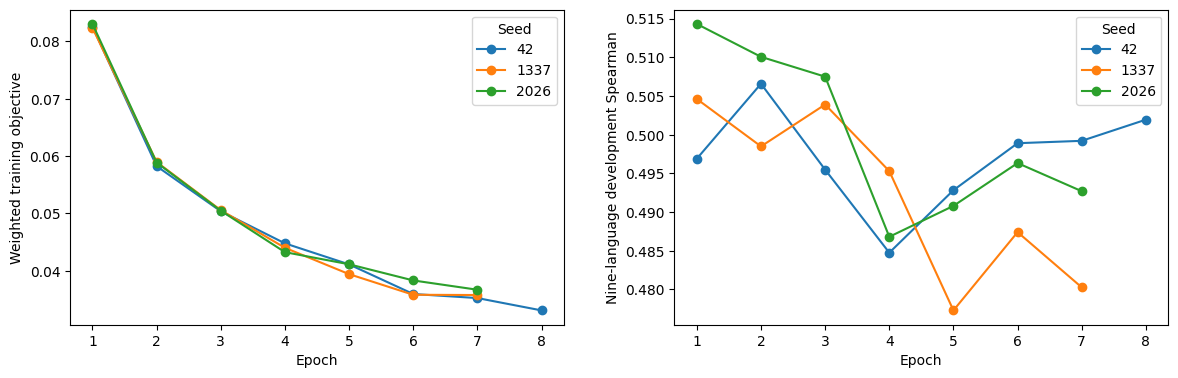

,candidate,macro_Spearman,macro_MAE,worst_language_change,eligible
0,convex-0,0.454294,0.287396,0.000000,False
1,convex-0.0625,0.483340,0.273840,-0.000074,True
2,convex-0.125,0.507460,0.260557,-0.004733,True
3,convex-0.25,0.531639,0.235844,-0.017058,True
4,convex-0.5,0.542239,0.195643,-0.058860,False
5,convex-0.75,0.535374,0.171936,-0.095763,False
6,convex-1,0.522083,0.172265,-0.182408,False
7,nonnegative-0,0.469133,0.179433,-0.140318,False
8,nonnegative-0.01,0.469262,0.179394,-0.140141,False
9,nonnegative-0.1,0.470470,0.179052,-0.132175,False


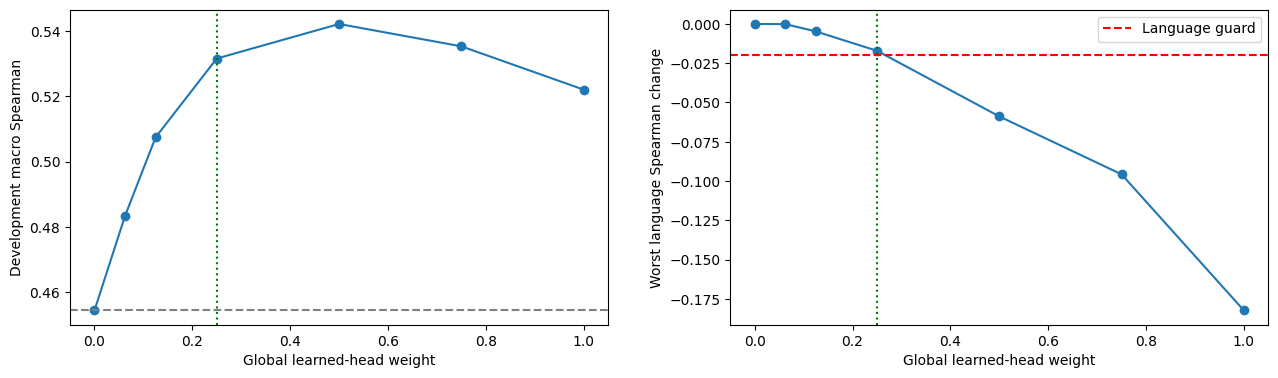

In [10]:
fits=results['learned_component']['fits']
display(pd.DataFrame([{'seed':run['seed'],'best_epoch':run['best_epoch'],'epochs_completed':len(run['history'])} for run in fits]))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for run in fits:
    history=pd.DataFrame([{'epoch':r['epoch'],'objective':r['training_objective'],'Spearman':r['validation']['macro_spearman']} for r in run['history']])
    axes[0].plot(history.epoch,history.objective,marker='o',label=str(run['seed']))
    axes[1].plot(history.epoch,history.Spearman,marker='o',label=str(run['seed']))
axes[0].set(xlabel='Epoch',ylabel='Weighted training objective');axes[1].set(xlabel='Epoch',ylabel='Nine-language development Spearman')
for ax in axes:ax.legend(title='Seed')
show(fig,'sts_selected_training_curves.png')
rows=[]
for candidate in results['global_prior_comparison']:
    value=candidate['validation'];deltas=[value['languages'][lang]['spearman']-results['baseline']['validation']['languages'][lang]['spearman'] for lang in LANGUAGES]
    rows.append({'candidate':candidate['name'],'macro_Spearman':value['macro_spearman'],'macro_MAE':value['macro_mae'],'worst_language_change':min(deltas),'eligible':candidate['promotion_eligible']})
policies=pd.DataFrame(rows);display(policies)
fig,axes=plt.subplots(1,2,figsize=(13,4));blend=policies[policies.candidate.str.startswith('convex-')].copy();blend['weight']=blend.candidate.str.replace('convex-','').astype(float)
axes[0].plot(blend.weight,blend.macro_Spearman,marker='o');axes[0].axhline(results['baseline']['validation']['macro_spearman'],color='gray',linestyle='--');axes[0].axvline(.25,color='green',linestyle=':');axes[0].set(xlabel='Global learned-head weight',ylabel='Development macro Spearman')
axes[1].plot(blend.weight,blend.worst_language_change,marker='o');axes[1].axhline(-.02,color='red',linestyle='--',label='Language guard');axes[1].axvline(.25,color='green',linestyle=':');axes[1].set(xlabel='Global learned-head weight',ylabel='Worst language Spearman change');axes[1].legend()
show(fig,'sts_global_prior_selection.png')

## Optional fresh training

A fresh run is opt-in and gets its own ignored output path. It does not replace selected weights, repeat test evaluation, or claim byte-identical results across framework versions. The root `train.py` command runs the complete fixed comparison; this cell demonstrates one selected-family seed using the visible loop.

In [11]:
RUN_FRESH_TRAINING=False
if RUN_FRESH_TRAINING:
    config={'name':'ranking0.1','hidden':128,'dropout':.2,'lr':.001,'weight_decay':.01,'ranking_weight':.1}
    component,new_history=fit(nx,ty,tl,nv,vy,vl,config,42,maximum=50)
    torch.save(component,RUN/'fresh-seed-42.pt')
    display(pd.DataFrame([{'fresh_seed':42,'best_epoch':new_history['best_epoch'],'epochs_completed':len(new_history['history'])}]))
else:
    print('Full training is opt-in; saved fitted checkpoints and authentic histories were replayed above.')

Full training is opt-in; saved fitted checkpoints and authentic histories were replayed above.


The global mixture improves development ranking while keeping Algerian Arabic and Indonesian losses within the preset guard. Punjabi remains weak and negatively correlated on development; it is retained, not relabeled or excluded. The split reuses sentences, development selection was repeated, and three language tests were previously observed. The separate aggregate-analysis notebook reads the final saved report without reopening gold.